# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [3]:
%pip install numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 8.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 14.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 14.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 8.5 MB/s  0:00:00 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent, EpsilonGreedyAlphaAgent, UCBAgent, HumanRuleAgent, LinearRegressionAgent, IgnoreConditions

## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [3]:
TEAM_LOG_FILES = [
    # "fishing_log_member1.json",
    # "fishing_log_member2.json",
    # "fishing_log_member3.json",
    "logs/fishing_log_lugotorr.json",
    "logs/fishing_log_castrola.json",
    "logs/fishing_log_gonzalea.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
# spots, catches = choices(logs[0], season=1)

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [4]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


In [5]:
"""
    For each season of a game log, return the spots chosen and the true means.

    Returns a dictionary {season number: {...}}. For seasons without a change, true_means_after_shift and shift_day are None.
"""
def read_log(log):
    seasons = {}
    for r in log["rounds"]:
        seasons[r["round"]] = {
            "options": [c["spot"] for c in r["choices"]],
            "true_means": r["true_means"],
            "true_means_after_shift": r["true_means_after_shift"],
            "shift_day": r["shift_day"],
        }
    return seasons

In [9]:
def score_season(data):
    """Min-max score of one season: 1 = always the best spot, 0 = always the worst.

    data: one season from read_log (spots chosen, true means and, for
    Season 3, the means after the change and the change day).
    Each day is scored with the means in force that day, then the days are averaged.
    """
    day_scores = []
    for day, spot in enumerate(data["options"], start=1):
        # Means in force on this day (in Season 3 they change on shift_day)
        if data["shift_day"] is None or day < data["shift_day"]:
            means = data["true_means"]
        else:
            means = data["true_means_after_shift"]

        best = max(means)
        worst = min(means)
        if best == worst:
            day_scores.append(1.0)  # all spots equal: any choice is the best one
        else:
            day_scores.append((means[spot] - worst) / (best - worst))

    return sum(day_scores) / len(day_scores)


def evaluate_agent(log):
    """Score every season of a log. Returns {season number: score}."""
    scores = {}
    for season, data in read_log(log).items():
        scores[season] = score_season(data)
    return scores


In [ ]:
# Task 2
for path, log in zip(TEAM_LOG_FILES, logs):
    member_name = path.split("_")[-1].replace(".json", "")
    for season in [1, 2, 3]:
        human_spots, _ = choices(log, season)
        bay = FishingBay.from_log(log, season)
        play(HumanRuleAgent(k=6, seed=0), bay)
        rule_spots = [spot for spot, catch in bay.history]
        same = sum(h == r for h, r in zip(human_spots, rule_spots))
        print(f"{member_name.upper():<10} Season {season}: rule = player on {same}/{len(human_spots)} days")

LUGOTORR   Season 1: rule = player on 3/30 days
LUGOTORR   Season 2: rule = player on 3/10 days
LUGOTORR   Season 3: rule = player on 14/30 days
CASTROLA   Season 1: rule = player on 5/30 days
CASTROLA   Season 2: rule = player on 3/10 days
CASTROLA   Season 3: rule = player on 11/30 days
GONZALEA   Season 1: rule = player on 30/30 days
GONZALEA   Season 2: rule = player on 5/10 days
GONZALEA   Season 3: rule = player on 30/30 days


In [ ]:
# Task 3 (a): team scores per season
print("--- Team Scores (0 = worst, 1 = best) ---")
for path, log in zip(TEAM_LOG_FILES, logs):
    member_name = path.split("_")[-1].replace(".json", "")
    scores = evaluate_agent(log)
    print(f"Player {member_name.upper()}:")
    for s, score in scores.items():
        print(f"  Season {s}: Score = {score:.3f}")

--- Team Scores (0 = worst, 1 = best) ---
Player LUGOTORR:
  Season 1: Score = 0.587
  Season 2: Score = 0.704
  Season 3: Score = 0.429
Player CASTROLA:
  Season 1: Score = 0.623
  Season 2: Score = 0.367
  Season 3: Score = 0.733
Player GONZALEA:
  Season 1: Score = 0.920
  Season 2: Score = 0.876
  Season 3: Score = 0.554


In [ ]:
# Task 3 (b): the same strategy (random) on 1000 bays per season
print("\n--- Proving the metric separates decisions from luck ---")
for season in [1, 2, 3]:
    catches, scores, lucks = [], [], []
    for seed in range(1000):
        bay = FishingBay(season=season, seed=seed)
        total = play(RandomAgent(seed=seed), bay)
        truth = bay.reveal()
        data = {
            "options": [spot for spot, catch in bay.history],
            "true_means": truth["means"],
            "true_means_after_shift": truth.get("means_after_change"),
            "shift_day": truth.get("change_day"),
        }
        expected = 0.0
        for day, spot in enumerate(data["options"], start=1):
            if data["shift_day"] is None or day < data["shift_day"]:
                expected += data["true_means"][spot]
            else:
                expected += data["true_means_after_shift"][spot]
        catches.append(total)
        scores.append(score_season(data))
        lucks.append(total - expected)
    print(f"Season {season}: corr(total catch, luck) = {np.corrcoef(catches, lucks)[0, 1]:.2f} | "
          f"corr(score, luck) = {np.corrcoef(scores, lucks)[0, 1]:.2f}")


--- Proving the metric separates decisions from luck ---
Season 1: corr(total catch, luck) = 0.22 | corr(score, luck) = -0.10
Season 2: corr(total catch, luck) = 0.53 | corr(score, luck) = 0.02
Season 3: corr(total catch, luck) = 0.44 | corr(score, luck) = -0.01


In [ ]:
# Task 3 (c): Season 3, who adapted to the change and how fast?
print("\n--- Season 3: adaptation to the change ---")
for path, log in zip(TEAM_LOG_FILES, logs):
    member_name = path.split("_")[-1].replace(".json", "")
    data = read_log(log)[3]
    shift = data["shift_day"]
    best_after = int(np.argmax(data["true_means_after_shift"]))
    days_on_best = [day for day, spot in enumerate(data["options"], start=1)
                    if day >= shift and spot == best_after]
    if days_on_best:
        delay = f"first fished it on day {days_on_best[0]} ({days_on_best[0] - shift} days after the change)"
    else:
        delay = "never fished it"
    print(f"{member_name.upper():<10} new best spot = {best_after}: {delay} | "
          f"days on it after the change: {len(days_on_best)}/{len(data['options']) - shift + 1}")


--- Season 3: adaptation to the change ---
LUGOTORR   new best spot = 4: first fished it on day 19 (3 days after the change) | days on it after the change: 4/15
CASTROLA   new best spot = 4: never fished it | days on it after the change: 0/15
GONZALEA   new best spot = 1: first fished it on day 26 (10 days after the change) | days on it after the change: 5/15


What we run. 
(a) The score of each team member in each season. (b) A random strategy on 1000 random bays per season; for each bay, luck = total catch − expected catch. (c) For Season 3, the first day each member fished the new best spot after the change (day 16).

Why. 
Task 3 asks for a measure that separates decisions from luck, and to show it with the simulator. If the score only reflects decisions, it should not be correlated with luck.

What we observe. 
The total catch is correlated with luck, but the score is not: the score depends on the spots chosen, not on the noise of the catches. In Season 3, Lugotorr reached the new best spot 3 days after the change, Gonzalea 10 days after, and Castrola never fished it.

## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

--- Season 1 Summary ---
         Random: Mean = 181.3 kg | Std Dev = 34.1 kg
     Human Rule: Mean = 224.9 kg | Std Dev = 44.1 kg
 Epsilon-Greedy: Mean = 228.9 kg | Std Dev = 34.8 kg
            UCB: Mean = 237.0 kg | Std Dev = 36.2 kg

--- Season 2 Summary ---
         Random: Mean = 61.2 kg | Std Dev = 14.4 kg
     Human Rule: Mean = 69.7 kg | Std Dev = 14.0 kg
 Epsilon-Greedy: Mean = 69.5 kg | Std Dev = 13.0 kg
            UCB: Mean = 70.5 kg | Std Dev = 13.1 kg

--- Season 3 Summary ---
         Random: Mean = 182.7 kg | Std Dev = 26.7 kg
     Human Rule: Mean = 206.4 kg | Std Dev = 38.6 kg
 Epsilon-Greedy: Mean = 216.2 kg | Std Dev = 31.3 kg
            UCB: Mean = 214.3 kg | Std Dev = 34.3 kg



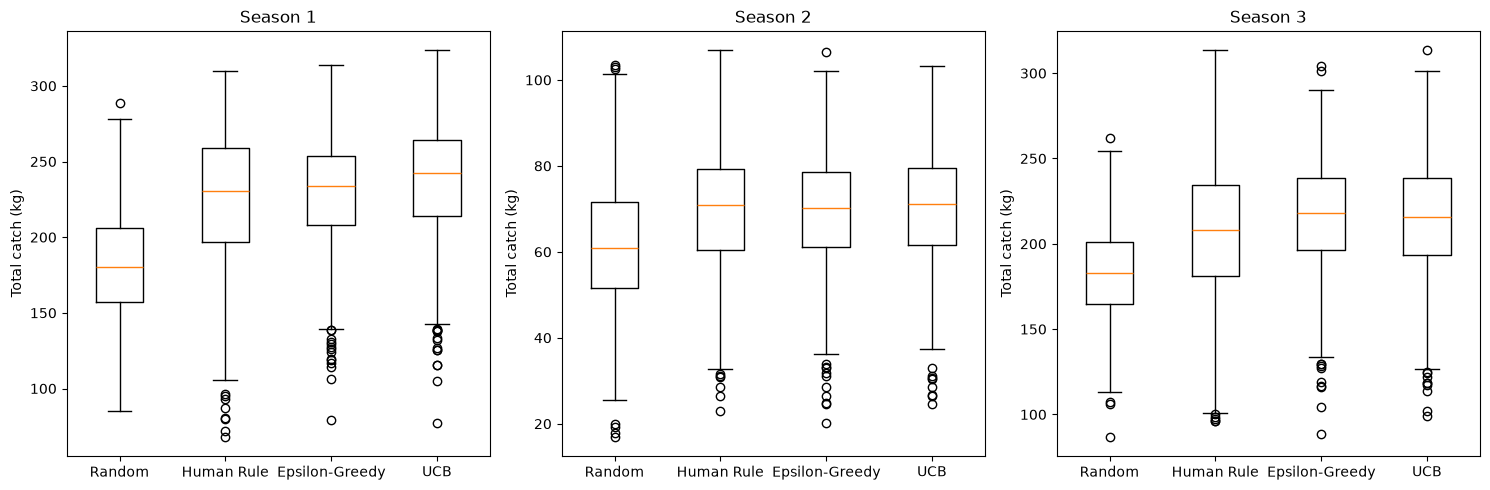

In [6]:
n_bays = 1000
seasons = [1, 2, 3]

def get_agents(seed=0):
    return {
        "Random": RandomAgent(seed=seed),
        "Human Rule": HumanRuleAgent(k=6, seed=seed),
        "Epsilon-Greedy": EpsilonGreedyAlphaAgent(epsilon=0.1, alpha=0.5, seed=seed),
        "UCB": UCBAgent(c=1.0, seed=seed)
    }

results = {s: {name: [] for name in get_agents()} for s in seasons}

for season in seasons:
    for seed in range(n_bays):
        bay = FishingBay(season=season, seed=seed)
        agents = get_agents(seed)

        for name, agent in agents.items():
            total_catch = play(agent, bay)
            results[season][name].append(total_catch)

    # Print the statistical summary for the season
    print(f"--- Season {season} Summary ---")
    for name in results[season].keys():
        data = results[season][name]
        print(f"{name:>15}: Mean = {np.mean(data):.1f} kg | Std Dev = {np.std(data):.1f} kg")
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, season in enumerate(seasons):
    ax = axes[i]
    names = list(results[season].keys())
    data_plot = [results[season][name] for name in names]

    ax.boxplot(data_plot, tick_labels=names)
    ax.set_title(f"Season {season}")
    ax.set_ylabel("Total catch (kg)")

plt.tight_layout()
plt.show()

What we run:
Every agent (Random, Human Rule, ε-greedy with ε = 0.1 and α = 0.5, UCB with c = 1) on the same 1000 random bays for each season.

Why:
Using the same bays for all agents makes the comparison fair: the differences come from the decisions, not from the bays.

What we observe:
All learning agents beat Random by far. UCB is best in Season 1 (237.0 kg) and Season 2 (70.5 kg, almost tied with the others), and ε-greedy is best in Season 3 (216.2 kg). The Human Rule has the widest distribution: it decides after one catch per spot and sometimes stays at a bad spot.

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [7]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)

agents_dict = get_agents(0)  # same agents as Section 1, fixed seed for reproducibility

for path, log in zip(TEAM_LOG_FILES, logs):
    # Player name from the file name (e.g. "gonzalea")
    member_name = path.split("_")[-1].replace(".json", "")
    print(f"=== Player: {member_name.upper()} ===")

    for season in [1, 2, 3]:
        # 1. Spots chosen and catches of the player in this season
        spots, catches = choices(log, season=season)
        human_total = sum(catches)

        print(f"--- Season {season} ---")
        print(f"  {'Human':>15} : {human_total:.1f} kg")

        # 2. Rebuild the exact bay the player fished (same catch on every day)
        bay = FishingBay.from_log(log, season=season)

        # 3. Each agent plays that same bay once, like the player did
        for name, agent in agents_dict.items():
            agent_total = play(agent, bay)
            diff = agent_total - human_total
            print(f"  {name:>15} : {agent_total:.1f} kg (Diff vs Human: {diff:+.1f} kg)")
    print()

=== Player: LUGOTORR ===
--- Season 1 ---
            Human : 226.0 kg
           Random : 231.9 kg (Diff vs Human: +5.9 kg)
       Human Rule : 264.6 kg (Diff vs Human: +38.6 kg)
   Epsilon-Greedy : 266.3 kg (Diff vs Human: +40.3 kg)
              UCB : 259.2 kg (Diff vs Human: +33.2 kg)
--- Season 2 ---
            Human : 69.3 kg
           Random : 73.1 kg (Diff vs Human: +3.8 kg)
       Human Rule : 72.1 kg (Diff vs Human: +2.8 kg)
   Epsilon-Greedy : 65.8 kg (Diff vs Human: -3.5 kg)
              UCB : 65.6 kg (Diff vs Human: -3.7 kg)
--- Season 3 ---
            Human : 162.0 kg
           Random : 165.9 kg (Diff vs Human: +3.9 kg)
       Human Rule : 152.8 kg (Diff vs Human: -9.2 kg)
   Epsilon-Greedy : 177.8 kg (Diff vs Human: +15.8 kg)
              UCB : 172.0 kg (Diff vs Human: +10.0 kg)

=== Player: CASTROLA ===
--- Season 1 ---
            Human : 225.4 kg
           Random : 214.4 kg (Diff vs Human: -11.0 kg)
       Human Rule : 204.4 kg (Diff vs Human: -21.0 kg)
   Epsi

What we run. 
Each agent plays once, the exact bays our team members played, and we compare with the member's real total.

Why. 
To see whether, and where, the agents do better than us on the same bays.

What we observe. 
The learning agents beat Lugotorr and Castrola in Seasons 1 and 3. On Gonzalea's bays, the Human Rule and UCB make the same decisions as Gonzalea in Seasons 1 and 3 (same totals), while Gonzalea beats all agents in Season 2 by stopping exploration at the first catch above 8 kg. Random sometimes beats a member: one run on one bay depends on luck.

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

--- Experimenting with longer seasons (150 days) ---

Simulating Season 2...
Season 2 -          Random: Mean = 910.0 kg
Season 2 -      Human Rule: Mean = 1144.6 kg
Season 2 -  Epsilon-Greedy: Mean = 1209.4 kg
Season 2 -             UCB: Mean = 1265.9 kg

Simulating Season 3...
Season 3 -          Random: Mean = 913.0 kg
Season 3 -      Human Rule: Mean = 1058.4 kg
Season 3 -  Epsilon-Greedy: Mean = 1177.9 kg
Season 3 -             UCB: Mean = 1148.1 kg


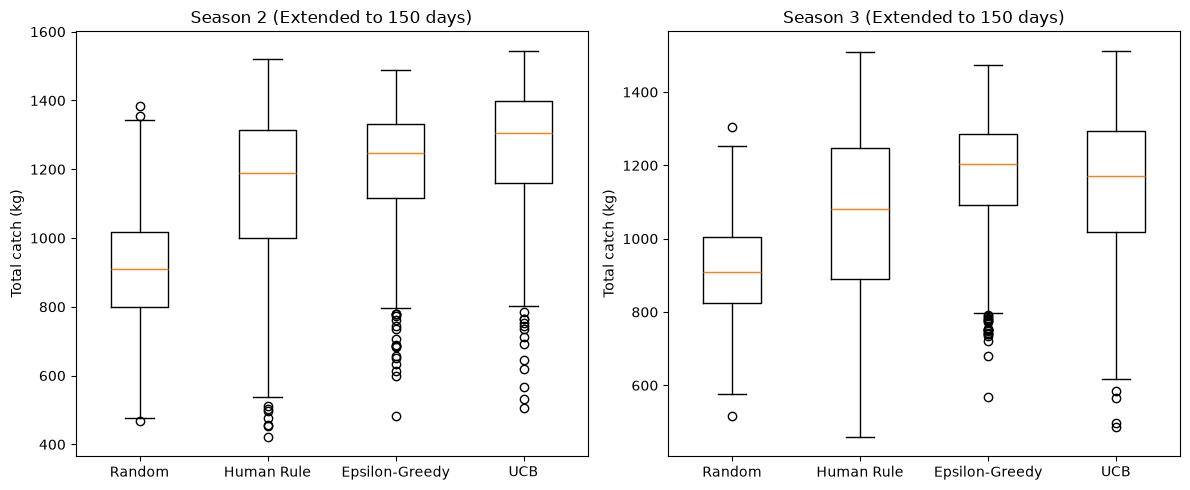

In [8]:
long_days = 150
n_bays = 1000
test_seasons = [2, 3]

print(f"--- Experimenting with longer seasons ({long_days} days) ---")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, test_season in enumerate(test_seasons):
    shift = 30 if test_season == 3 else None
    print(f"\nSimulating Season {test_season}...")
    
    results_long = {name: [] for name in get_agents().keys()}
    
    for seed in range(n_bays):
        bay = FishingBay(season=test_season, seed=seed, days=long_days, shift_day=shift)
        agents = get_agents(seed)
        
        for name, agent in agents.items():
            catch = play(agent, bay)
            results_long[name].append(catch)
            
    # Print summary
    for name, data in results_long.items():
        print(f"Season {test_season} - {name:>15}: Mean = {np.mean(data):.1f} kg")
        
    # Plot distribution
    ax = axes[i]
    names = list(results_long.keys())
    data_plot = [results_long[name] for name in names]
    ax.boxplot(data_plot, tick_labels=names)
    ax.set_title(f"Season {test_season} (Extended to {long_days} days)")
    ax.set_ylabel("Total catch (kg)")

plt.tight_layout()
plt.show()

What we run. 
The same agents on longer seasons: Season 2 without change, Season 3 with a change on day 30.

Why. 
To explain why the winners of Seasons 2 and 3 win: is it the short length, or the change?

What we observe. 
With 150 days and no change, UCB wins clearly (1265.9 kg vs 1209.4 for ε-greedy), so the near tie in Season 2 comes from its length: in 10 days, exploring 5 spots takes half the season. With a change, ε-greedy wins (1177.9 vs 1148.1 for UCB): its constant α forgets the old catches, while UCB's sample average reacts slowly. Best agent: Season 2, UCB (by a small margin); Season 3, ε-greedy.

## 4. One parameter

Study the effect of one parameter of one method.

--- Season 1 ---
  epsilon = 0.0  : Mean = 234.2 kg
  epsilon = 0.05 : Mean = 231.6 kg
  epsilon = 0.1  : Mean = 228.9 kg
  epsilon = 0.2  : Mean = 223.7 kg
  epsilon = 0.3  : Mean = 218.3 kg
  epsilon = 0.5  : Mean = 207.9 kg
--- Season 2 ---
  epsilon = 0.0  : Mean = 70.5 kg
  epsilon = 0.05 : Mean = 70.1 kg
  epsilon = 0.1  : Mean = 69.5 kg
  epsilon = 0.2  : Mean = 68.6 kg
  epsilon = 0.3  : Mean = 67.7 kg
  epsilon = 0.5  : Mean = 65.9 kg
--- Season 3 ---
  epsilon = 0.0  : Mean = 219.5 kg
  epsilon = 0.05 : Mean = 218.2 kg
  epsilon = 0.1  : Mean = 216.2 kg
  epsilon = 0.2  : Mean = 213.1 kg
  epsilon = 0.3  : Mean = 209.6 kg
  epsilon = 0.5  : Mean = 202.4 kg


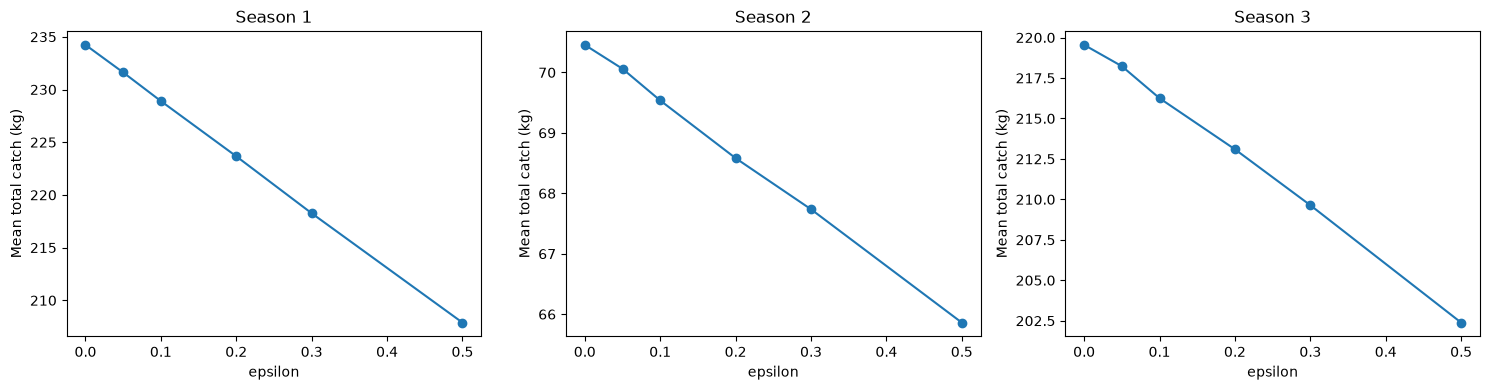

In [9]:
epsilons = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
n_bays = 1000
seasons = [1, 2, 3]

# Only ε changes; α stays at 0.5 so that the effect comes from ε alone
eps_results = {season: [] for season in seasons}

for season in seasons:
    print(f"--- Season {season} ---")
    for eps in epsilons:
        totals = []
        for seed in range(n_bays):
            bay = FishingBay(season=season, seed=seed)
            agent = EpsilonGreedyAlphaAgent(epsilon=eps, alpha=0.5, seed=seed)
            totals.append(play(agent, bay))
        eps_results[season].append(np.mean(totals))
        print(f"  epsilon = {eps:<5}: Mean = {np.mean(totals):.1f} kg")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, season in zip(axes, seasons):
    ax.plot(epsilons, eps_results[season], marker="o")
    ax.set_title(f"Season {season}")
    ax.set_xlabel("epsilon")
    ax.set_ylabel("Mean total catch (kg)")
plt.tight_layout()
plt.show()

What we run. 
ε-greedy with ε = 0, 0.05, 0.1, 0.2, 0.3, 0.5 (α = 0.5) on 1000 bays per season.

Why. 
To study how much random exploration this game needs.

What we observe. 
In every season, the smaller ε, the better (Season 1: 234.2 kg with ε = 0 vs 207.9 with ε = 0.5). The drop is largest in Season 1 (26 kg) and smallest in Season 2 (4.6 kg). With α = 0.5 the estimates move a lot with each noisy catch, so the agent already switches spots without random exploration; ε only adds costly random days. The panels have different y-scales.

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

Random contextual agent: 1945.7 kg over 300 days

--- Evaluating Contextual Agents (1000 bays, 300 days per bay) ---
Regret = best possible - total catch (kg), lower is better
                 Random: Mean catch = 1747.9 kg | Mean regret = 1215.2 | 95th percentile = 1997.8 | Bays with regret > 500 = 994
        UCB (ignores x): Mean catch = 2769.5 kg | Mean regret =  193.6 | 95th percentile =  592.9 | Bays with regret > 500 = 74
 Predictions only (m=1): Mean catch = 2835.5 kg | Mean regret =  127.6 | 95th percentile =  354.0 | Bays with regret > 500 = 25
          Warm-up (m=3): Mean catch = 2823.1 kg | Mean regret =  140.0 | 95th percentile =  266.3 | Bays with regret > 500 = 1
          Warm-up (m=4): Mean catch = 2810.8 kg | Mean regret =  152.3 | 95th percentile =  253.4 | Bays with regret > 500 = 2


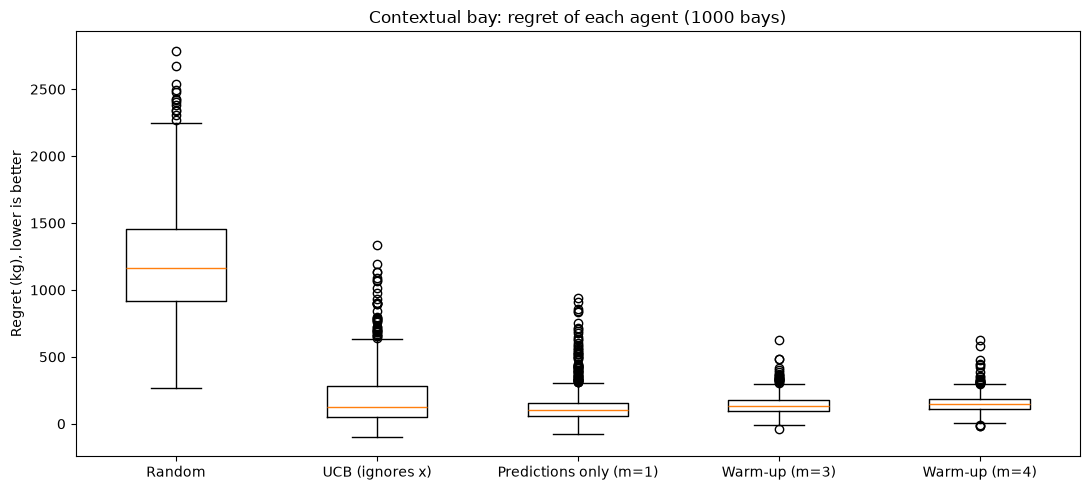

In [13]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

n_bays = 1000
print(f"\n--- Evaluating Contextual Agents ({n_bays} bays, 300 days per bay) ---")

def get_ctx_agents(seed=0):
    return {
        "Random": RandomContextualAgent(seed=seed),
        "UCB (ignores x)": IgnoreConditions(UCBAgent(c=1.0, seed=seed)),  # best agent of Part III
        "Predictions only (m=1)": LinearRegressionAgent(m=1, seed=seed),  # the case that fails
        "Warm-up (m=3)": LinearRegressionAgent(m=3, seed=seed),           # fix
        "Warm-up (m=4)": LinearRegressionAgent(m=4, seed=seed),           # fix, 4 data points = 4 weights
    }

totals = {name: [] for name in get_ctx_agents()}
regrets = {name: [] for name in get_ctx_agents()}
for seed in range(n_bays):
    bay = ContextualBay(seed=seed)
    for name, agent in get_ctx_agents(seed).items():
        total = play(agent, bay)
        totals[name].append(total)
        regrets[name].append(bay.best_possible() - total)

print("Regret = best possible - total catch (kg), lower is better")
for name in totals:
    r = np.array(regrets[name])
    print(f"{name:>23}: Mean catch = {np.mean(totals[name]):6.1f} kg | Mean regret = {r.mean():6.1f}"
          f" | 95th percentile = {np.percentile(r, 95):6.1f} | Bays with regret > 500 = {(r > 500).sum()}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([regrets[name] for name in regrets], tick_labels=list(regrets))
ax.set_title(f"Contextual bay: regret of each agent ({n_bays} bays)")
ax.set_ylabel("Regret (kg), lower is better")
plt.tight_layout()
plt.show()

What we run. 
On 1000 contextual bays (300 days): Random, UCB ignoring the conditions (best agent of Part III), and a linear regression per spot with m = 1 (acting only on the predictions) and with a warm-up of m = 3 and m = 4 visits per spot.

Why. 
Task 6: predict the catch from the conditions, compare with Part III, and find when acting only on the predictions fails.

What we observe. 
Using the conditions helps: the regression has a mean regret of 127.6 kg vs 193.6 for UCB. Acting only on the predictions (m = 1) has the best mean but 25 disastrous bays (regret > 500); the warm-up (m = 3) costs a little on average (140.0) but leaves only 1.

In [14]:
# A case where acting only on the predictions fails: the bay where it had the highest regret
seed = int(np.argmax(regrets["Predictions only (m=1)"]))
print(f"Worst bay for predictions only: seed {seed}\n")

for name, agent in [("Predictions only (m=1)", LinearRegressionAgent(m=1, seed=seed)),
                    ("Warm-up (m=3)", LinearRegressionAgent(m=3, seed=seed)),
                    ("Warm-up (m=4)", LinearRegressionAgent(m=4, seed=seed))]:
    bay = ContextualBay(seed=seed)
    total = play(agent, bay)
    visits = np.bincount([spot for x, spot, catch in bay.history], minlength=5)
    print(f"{name:>23}: regret = {bay.best_possible() - total:6.1f} kg | days at each spot = {visits}")

best_spot = bay.reveal().argmax(axis=1)
print(f"{'Days each spot is best':>23}: {np.bincount(best_spot, minlength=5)}")

Worst bay for predictions only: seed 972

 Predictions only (m=1): regret =  940.8 kg | days at each spot = [  3 166  50   1  80]
          Warm-up (m=3): regret =  101.8 kg | days at each spot = [102   5   8 175  10]
          Warm-up (m=4): regret =  117.2 kg | days at each spot = [108   5  12 169   6]
 Days each spot is best: [120   1   0 175   4]


What we observe. 
On the worst bay for m = 1 (seed 972), Old Pier and Deep Channel are the best spots on 120 and 175 days, but the agent fished them only 3 days and 1 day: after a single catch its regression underestimated them and it never came back (regret 940.8 kg). With the warm-up (m = 3) it fished them 102 and 175 days (regret 101.8 kg). Fix: collect a few points per spot before trusting the regression.